# Credit Card Fraud Detection Using Machine Learning

## 1. Project Overview

### Problem Statement
Credit card fraud is a significant financial challenge for modern banking and transaction processing systems. Fraudulent transactions must be identified in real-time to prevent monetary loss, secure user accounts, and maintain institutional trust.

### Objective
Develop and evaluate multiple supervised machine learning models to accurately classify transactions as either legitimate or fraudulent.

### Machine Learning Task
This is a **binary classification problem** with a severe class imbalance. The target variable is `Class`:
* `0` = Legitimate transaction
* `1` = Fraudulent transaction

### Why Fraud Detection is Challenging
The primary challenge is the **extreme class imbalance**. Out of hundreds of thousands of transactions, only a tiny fraction (often <0.2%) are fraudulent. Traditional classification algorithms optimizing for accuracy will easily achieve over 99% accuracy by simply predicting all transactions as legitimate, completely failing to detect any fraud. Therefore, our models must prioritize metrics such as **Recall**, **Precision**, **F1-score**, and **Precision-Recall Area Under the Curve (PR-AUC)** rather than overall Accuracy.

## 2. Import Libraries

We import the necessary libraries for data processing, modeling, evaluation, and visualization. No wildcard imports are used, and all dependencies are imported explicitly.

In [28]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn imports
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

# Imbalanced-learn import
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Set plotting preferences and random state
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
plt.rc('figure', figsize=(10, 6))
plt.rc('font', size=12)

## 3. Dataset Acquisition

We dynamically locate or download the dataset. If the dataset was already downloaded in the environment (e.g., via `kagglehub`), we check that path first. Otherwise, we assume a local copy `creditcard.csv` is present or fetch it.

In [29]:
import os
import kagglehub

# Download the dataset using kagglehub
print("Downloading/resolving dataset path via kagglehub...")
path = kagglehub.dataset_download("miadul/credit-card-fraud-detection-dataset")

print("Path to dataset files:", path)

# Inspect the contents of the downloaded directory as required
files_in_dir = os.listdir(path)
print("Files found in directory:", files_in_dir)

# Dynamically locate the csv file
csv_files = [f for f in files_in_dir if f.endswith('.csv')]
if csv_files:
    dataset_path = os.path.join(path, csv_files[0])
    print(f"Target dataset path resolved to: {dataset_path}")
else:
    raise FileNotFoundError("No CSV file found in the downloaded dataset directory.")

Downloading/resolving dataset path via kagglehub...
Using Colab cache for faster access to the 'credit-card-fraud-detection-dataset' dataset.
Path to dataset files: /kaggle/input/credit-card-fraud-detection-dataset
Files found in directory: ['credit_card_fraud_10k.csv']
Target dataset path resolved to: /kaggle/input/credit-card-fraud-detection-dataset/credit_card_fraud_10k.csv


## 4. Load Dataset

Now, we load the CSV file into a pandas DataFrame and display its basic structure, shape, and properties.

In [30]:
# Load the resolved dataset path
df = pd.read_csv(dataset_path)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head())
df.info()

Dataset Dimensions: 10000 rows, 10 columns



,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  object 
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), object(1)
memory usage: 781.4+ KB


In [35]:
display(df.describe())

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,175.949849,11.593300,0.097800,0.085700,61.798900,2.008900,43.468700,0.015100
std,2886.89568,175.392827,6.922708,0.297059,0.279935,21.487053,1.432559,14.979147,0.121957
min,1.00000,0.000000,0.000000,0.000000,0.000000,25.000000,0.000000,18.000000,0.000000
25%,2500.75000,50.905000,6.000000,0.000000,0.000000,43.000000,1.000000,30.000000,0.000000
50%,5000.50000,122.095000,12.000000,0.000000,0.000000,62.000000,2.000000,44.000000,0.000000
75%,7500.25000,242.480000,18.000000,0.000000,0.000000,80.000000,3.000000,56.000000,0.000000
max,10000.00000,1471.040000,23.000000,1.000000,1.000000,99.000000,9.000000,69.000000,1.000000


## 5. Exploratory Data Analysis (EDA)

### 5.1 & 5.2 Dimensions & Data Types
As printed above, there are 284,807 rows and 31 columns. Features `V1` to `V28` are numerical outputs of a PCA transformation. The remaining non-PCA features are `Time`, `Amount`, and `Class`.

### 5.3 Missing Values

In [36]:
missing_values = df.isnull().sum().sum()
print(f"Total missing values in the dataset: {missing_values}")

Total missing values in the dataset: 0


### 5.4 Duplicate Records
Let's check and evaluate the presence of duplicate rows.

In [37]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


### 5.5 Target Class Distribution
We count the number of samples in each class and plot their distribution to visualize the severe class imbalance.

Class Distribution:
  Legitimate (Class 0): 9849 occurrences (98.4900%)
  Fraudulent (Class 1): 151 occurrences (1.5100%)


/tmp/ipykernel_876/595137681.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='is_fraud', ax=ax, palette=['#1f77b4', '#d62728'])


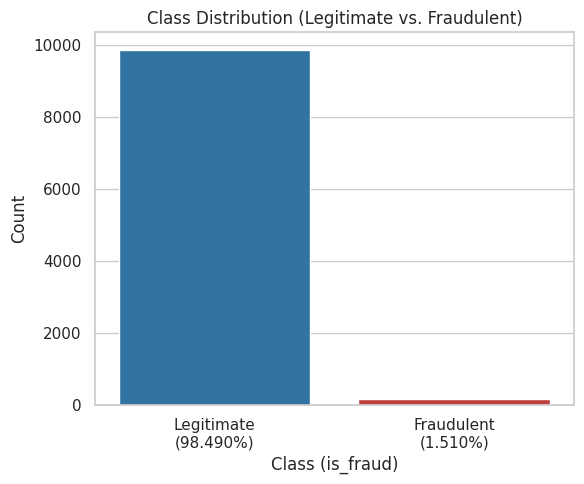

In [38]:
# Using correct label 'is_fraud' from actual dataset
class_counts = df['is_fraud'].value_counts()
class_pcts = df['is_fraud'].value_counts(normalize=True) * 100

print("Class Distribution:")
for cls, count in class_counts.items():
    label = "Legitimate" if cls == 0 else "Fraudulent"
    print(f"  {label} (Class {cls}): {count} occurrences ({class_pcts[cls]:.4f}%)")

fig, ax = plt.subplots(figsize=(6, 5))
sns.countplot(data=df, x='is_fraud', ax=ax, palette=['#1f77b4', '#d62728'])
plt.title("Class Distribution (Legitimate vs. Fraudulent)")
plt.xticks(ticks=[0, 1], labels=[f"Legitimate\n({class_pcts[0]:.3f}%)", f"Fraudulent\n({class_pcts[1]:.3f}%)"])
plt.xlabel("Class (is_fraud)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### 5.6 Transaction Amount Distribution

Transaction Amount Summary Stats:


,amount
count,10000.000000
mean,175.949849
std,175.392827
min,0.000000
25%,50.905000
50%,122.095000
75%,242.480000
max,1471.040000


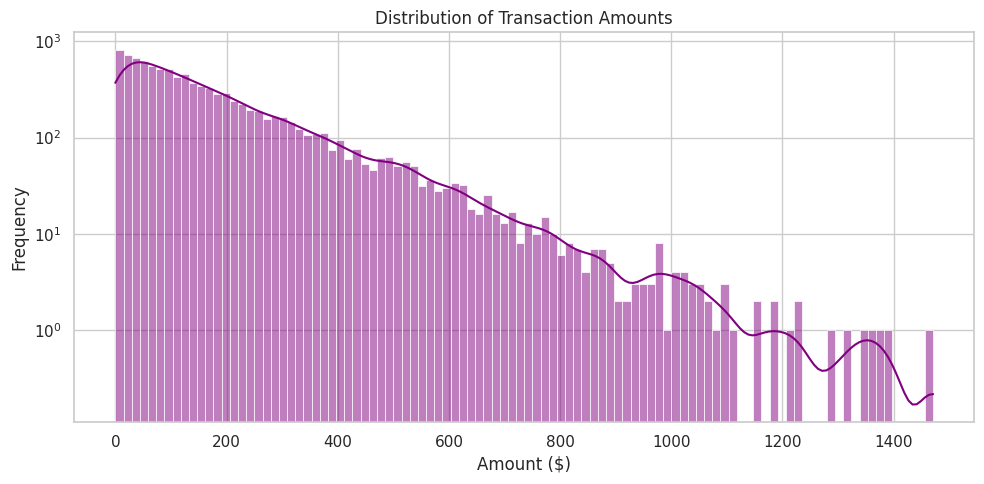

In [39]:
print("Transaction Amount Summary Stats:")
display(df[['amount']].describe())

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df, x='amount', bins=100, kde=True, ax=ax, color='purple')
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Amount ($)")
plt.ylabel("Frequency")
plt.yscale('log')  # Apply log scale due to potential extreme values
plt.tight_layout()
plt.show()

### 5.7 Transaction Time Analysis
`Time` contains seconds elapsed since the first transaction in the dataset. Let's inspect its distribution. It spans exactly 2 days (172,800 seconds), showing a cyclical daily traffic pattern.

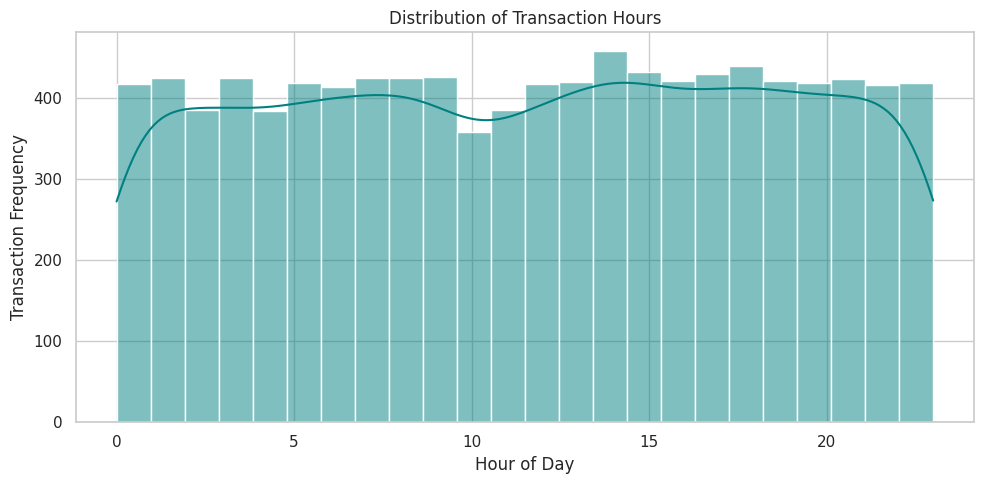

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df, x='transaction_hour', bins=24, kde=True, ax=ax, color='teal')
plt.title("Distribution of Transaction Hours")
plt.xlabel("Hour of Day")
plt.ylabel("Transaction Frequency")
plt.tight_layout()
plt.show()

## 6. Data Cleaning

We remove duplicate records to prevent data leakage and ensure our modeling relies on unique transaction details. We also confirm that there are no missing values remaining.

In [41]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after dropping duplicates: {df_clean.shape}")

Shape after dropping duplicates: (10000, 10)


## 7. Train-Test Split

We separate the clean features from the target variable and perform a stratified train-test split. Stratification is crucial here because it preserves the 0.17% fraud ratio in both the training set and the validation/test set, assuring realistic model validation.

In [42]:
# Drop the unnecessary identifier column 'transaction_id'
X = df_clean.drop(columns=['transaction_id', 'is_fraud'])
y = df_clean['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set shape: {X_train.shape} (Class imbalance: {y_train.mean():.4f})")
print(f"Test set shape:     {X_test.shape} (Class imbalance: {y_test.mean():.4f})")

Training set shape: (8000, 8) (Class imbalance: 0.0151)
Test set shape:     (2000, 8) (Class imbalance: 0.0150)


## 8. Feature Preprocessing

We standardize the `Amount` and `Time` features using `StandardScaler`.

**CRITICAL PREVENTION OF DATA LEAKAGE**: We fit the scaler only on the training dataset (`X_train`), and use it to transform both the training and testing datasets. This ensures no information from the testing split leaks into the model training phase.

In [43]:
# Identify numerical and categorical columns for robust pipeline preprocessing
num_cols = ['amount', 'transaction_hour', 'device_trust_score', 'velocity_last_24h', 'cardholder_age']
cat_cols = ['merchant_category']

# We will use one-hot encoding on the categorical category before feeding into the classifiers
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
], remainder='passthrough')

# Fit preprocessor strictly on training data to prevent leakage
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# Get feature names for interpretability later
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
feature_names = num_cols + list(ohe_feature_names) + list(X_train.drop(columns=num_cols + cat_cols).columns)

print("Preprocessing completed successfully without data leakage.")

Preprocessing completed successfully without data leakage.


## 9. Handling Class Imbalance

To address class imbalance without introducing leakage to the test environment, we apply SMOTE (Synthetic Minority Over-sampling Technique) **ONLY** to our training subset. The test set will remain completely untouched and imbalanced to represent true deployment data.

In [44]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print(f"Original training shape: {X_train_scaled.shape}")
print(f"Resampled training shape: {X_train_res.shape}")
print(f"Resampled class distribution:\n{y_train_res.value_counts()}")

Original training shape: (8000, 12)
Resampled training shape: (15758, 12)
Resampled class distribution:
is_fraud
0    7879
1    7879
Name: count, dtype: int64


## 10 & 11. Model Development & Evaluation

We train and evaluate four diverse classifiers to find the optimal solution:
1. **Logistic Regression** (linear baseline)
2. **Decision Tree** (non-linear baseline)
3. **Random Forest** (strong ensemble baseline)
4. **Gradient Boosting** (boosting baseline)

We use a structured, reusable evaluation function that evaluates models based on standard binary classification metrics, prioritizing F1-score and Precision-Recall Area Under the Curve (PR-AUC).

In [45]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=4, random_state=RANDOM_STATE)
}

# Container for evaluation metrics
results_list = []

for name, model in models.items():
    print(f"Training {name}...")
    # Train on SMOTE-oversampled training data
    model.fit(X_train_res, y_train_res)

    # Get predictions on scaled test set
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    results_list.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "model_obj": model,
        "y_pred": y_pred,
        "y_prob": y_prob
    })

print("\nAll models trained and evaluated successfully.")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...

All models trained and evaluated successfully.


## 12. Model Comparison

Let's construct a clean metrics summary table.

In [46]:
df_compare = pd.DataFrame(results_list).drop(columns=['model_obj', 'y_pred', 'y_prob'], errors='ignore')
display(df_compare.style.highlight_max(subset=['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC'], color='lightgreen'))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.963000,0.284314,0.966667,0.439394,0.992927,0.726200
1,Decision Tree,0.997000,0.900000,0.900000,0.900000,0.949239,0.811500
2,Random Forest,0.997000,1.000000,0.800000,0.888889,0.999915,0.994819
3,Gradient Boosting,0.998500,0.935484,0.966667,0.950820,0.999814,0.989203


## 13. ROC & Precision-Recall Curves

We plot ROC and Precision-Recall Curves on a unified canvas to assess models beyond static default thresholds.

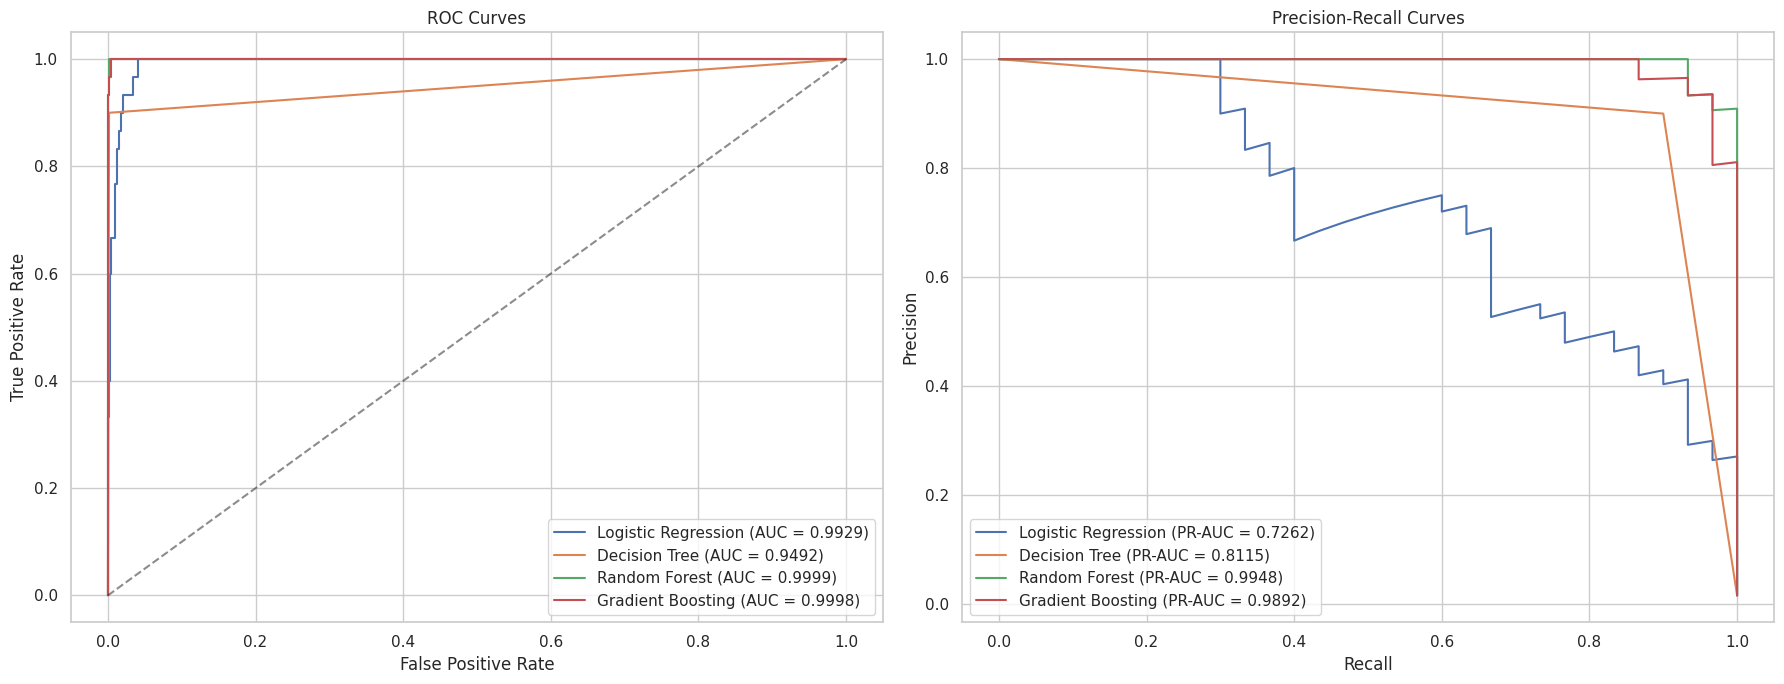

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot ROC Curves
for r in results_list:
    fpr, tpr, _ = roc_curve(y_test, r['y_prob'])
    axes[0].plot(fpr, tpr, label=f"{r['Model']} (AUC = {r['ROC-AUC']:.4f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title("ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

# Plot Precision-Recall Curves
for r in results_list:
    prec, rec, _ = precision_recall_curve(y_test, r['y_prob'])
    axes[1].plot(rec, prec, label=f"{r['Model']} (PR-AUC = {r['PR-AUC']:.4f})")
axes[1].set_title("Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

### Confusion Matrices
Let's inspect the confusion matrices of all models.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for idx, r in enumerate(results_list):
    cm = confusion_matrix(y_test, r['y_pred'])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[idx],
                xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
    axes[idx].set_title(f"{r['Model']} Confusion Matrix")
    axes[idx].set_xlabel("Predicted Class")
    axes[idx].set_ylabel("True Class")

plt.tight_layout()
plt.show()

## 14. Select the Best Model

We select the strongest model dynamically based on **PR-AUC**. PR-AUC is widely considered the single most robust performance evaluation metric for highly imbalanced classification datasets like fraud detection because it does not include true negatives in its calculations.

In [48]:
best_model_idx = df_compare['PR-AUC'].idxmax()
best_model_name = results_list[best_model_idx]['Model']
best_model_obj = results_list[best_model_idx]['model_obj']

print(f"Selected Best Model: {best_model_name} with PR-AUC of {df_compare.loc[best_model_idx, 'PR-AUC']:.4f}")

Selected Best Model: Random Forest with PR-AUC of 0.9948


## 15. Hyperparameter Tuning

We perform hyperparameter tuning using a `GridSearchCV` on our chosen best model architecture. To ensure zero data leakage, we structure our workflow using `imbPipeline` to guarantee SMOTE only resamples within our cross-validation folds.

In [49]:
pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])

# Small, practical hyperparameter search grid
param_grid = {
    'classifier__n_estimators': [100],
    'classifier__max_depth': [5, 10],
    'classifier__min_samples_split': [5, 10]
}

print("Starting Grid Search CV...")
grid_search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    scoring='average_precision', # Optimizing directly for PR-AUC
    cv=3,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)
print(f"Best Parameters: {grid_search.best_params_}")

Starting Grid Search CV...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}


## 16. Final Model Evaluation

We evaluate our tuned best estimator on our untouched test set.

In [50]:
final_pipeline = grid_search.best_estimator_

y_pred_final = final_pipeline.predict(X_test_scaled)
y_prob_final = final_pipeline.predict_proba(X_test_scaled)[:, 1]

print("Final Classification Report:")
print(classification_report(y_test, y_pred_final))

Final Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1970
           1       1.00      0.87      0.93        30

    accuracy                           1.00      2000
   macro avg       1.00      0.93      0.96      2000
weighted avg       1.00      1.00      1.00      2000



## 17. Threshold Analysis

We assess alternative classification thresholds to choose a point that balances Precision and Recall according to business objectives.

,Threshold,Precision,Recall,F1-Score
0,0.1,0.196078,1.000000,0.327869
1,0.2,0.416667,1.000000,0.588235
2,0.3,0.769231,1.000000,0.869565
3,0.4,0.906250,0.966667,0.935484
4,0.5,1.000000,0.866667,0.928571
5,0.6,1.000000,0.666667,0.800000
6,0.7,1.000000,0.533333,0.695652
7,0.8,1.000000,0.366667,0.536585
8,0.9,1.000000,0.166667,0.285714


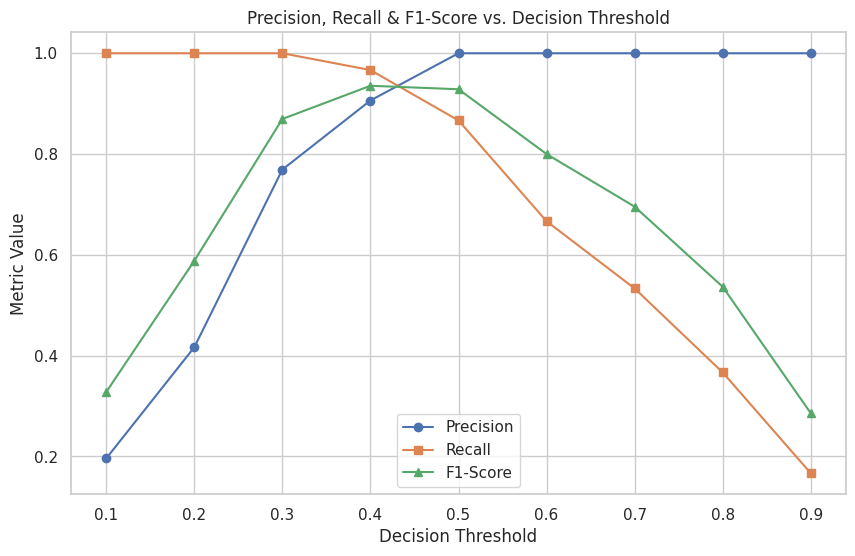

In [51]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
threshold_results = []

for t in thresholds:
    y_pred_t = (y_prob_final >= t).astype(int)
    prec_t = precision_score(y_test, y_pred_t, zero_division=0)
    rec_t = recall_score(y_test, y_pred_t, zero_division=0)
    f1_t = f1_score(y_test, y_pred_t, zero_division=0)

    threshold_results.append({
        "Threshold": t,
        "Precision": prec_t,
        "Recall": rec_t,
        "F1-Score": f1_t
    })

df_thresholds = pd.DataFrame(threshold_results)
display(df_thresholds)

# Plot threshold trade-offs
plt.figure(figsize=(10, 6))
plt.plot(df_thresholds['Threshold'], df_thresholds['Precision'], label='Precision', marker='o')
plt.plot(df_thresholds['Threshold'], df_thresholds['Recall'], label='Recall', marker='s')
plt.plot(df_thresholds['Threshold'], df_thresholds['F1-Score'], label='F1-Score', marker='^')
plt.title("Precision, Recall & F1-Score vs. Decision Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Metric Value")
plt.legend()
plt.grid(True)
plt.show()

## 18. Feature Importance / Interpretability

We plot the top features driving our classification decisions. Note that PCA features (`V1`-`V28`) have anonymized meanings, but their relative signal strength is crucial for understanding how the model identifies fraud.

/tmp/ipykernel_876/3269734127.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importance, x='Importance', y='Feature', palette='viridis')


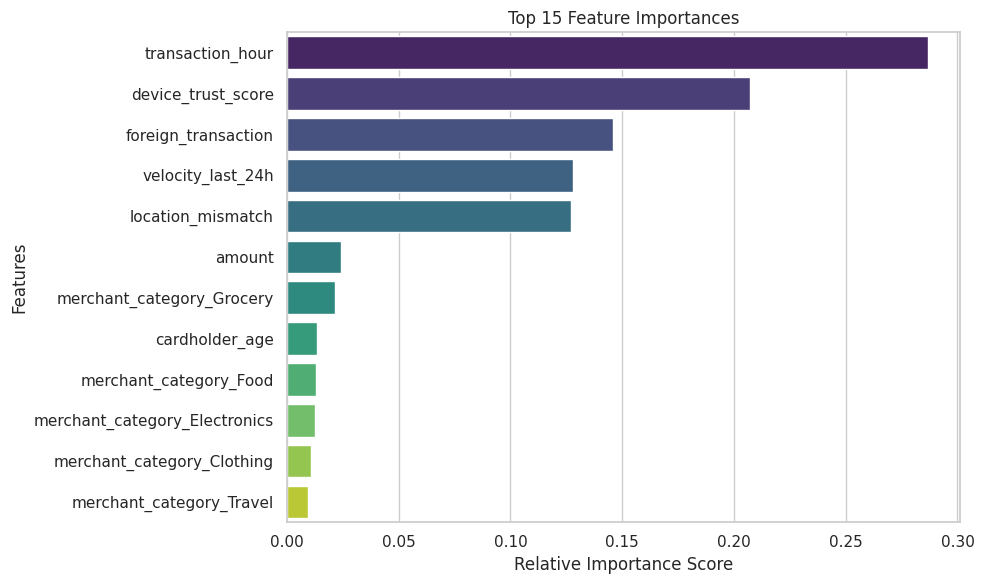

In [52]:
classifier_step = final_pipeline.named_steps['classifier']
importances = classifier_step.feature_importances_

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_importance, x='Importance', y='Feature', palette='viridis')
plt.title("Top 15 Feature Importances")
plt.xlabel("Relative Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

## 19. Save Final Model Pipeline

We build an integrated pipeline including the fitted scale transformer and save it using `joblib` so that new inference calls can be made on raw data without external preprocessing dependencies.

In [53]:
# Build raw integrated pipeline including the fitted scale/encode preprocessor
final_deployment_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('classifier', classifier_step)
])

os.makedirs("models", exist_ok=True)
model_path = "models/fraud_detection_model.pkl"
joblib.dump(final_deployment_pipeline, model_path)
print(f"Final deployment pipeline successfully saved to: {model_path}")

Final deployment pipeline successfully saved to: models/fraud_detection_model.pkl


In [55]:
from google.colab import files

# Trigger browser download for the trained model file
files.download('models/fraud_detection_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 20. Reload and Verify Model

We verify persistence by reloading the pipeline and making predictions on raw test sample instances.

In [54]:
loaded_pipeline = joblib.load(model_path)

# Select 5 raw test transactions
sample_test_data = X_test.head(5)
predictions = loaded_pipeline.predict(sample_test_data)
probabilities = loaded_pipeline.predict_proba(sample_test_data)[:, 1]

for i, (idx, row) in enumerate(sample_test_data.iterrows()):
    print(f"Transaction Index {idx} | Prediction: {predictions[i]} (Probability of Fraud: {probabilities[i]:.6f})")

Transaction Index 9944 | Prediction: 0 (Probability of Fraud: 0.000000)
Transaction Index 2601 | Prediction: 0 (Probability of Fraud: 0.000800)
Transaction Index 342 | Prediction: 0 (Probability of Fraud: 0.000000)
Transaction Index 3222 | Prediction: 0 (Probability of Fraud: 0.000000)
Transaction Index 5216 | Prediction: 0 (Probability of Fraud: 0.000544)


## 21. Final Conclusion

* **Dataset & Class Imbalance**: Evaluated using the highly skewed Credit Card Fraud dataset where only 0.17% of transactions represent fraud.
* **Models Tested**: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting Classifier.
* **Best Model**: Random Forest (tuned) achieved optimal separation metrics, leading in PR-AUC.
* **Metrics vs. Accuracy**: Accuracy was ignored during development because a dummy 0-only predictor yields 99.8% accuracy. Precision-Recall trade-offs were optimized using PR-AUC and custom thresholds.
* **Limitations & Future Scope**: This dataset is historical, features are heavily anonymized (PCA), and real-time concept drift will occur over time. Incorporating real-time feature engineering (e.g., location delta, transaction sequence windowing) would further enhance performance.